<a href="https://colab.research.google.com/github/ensogma/dls/blob/main/hw_2_text_classification_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

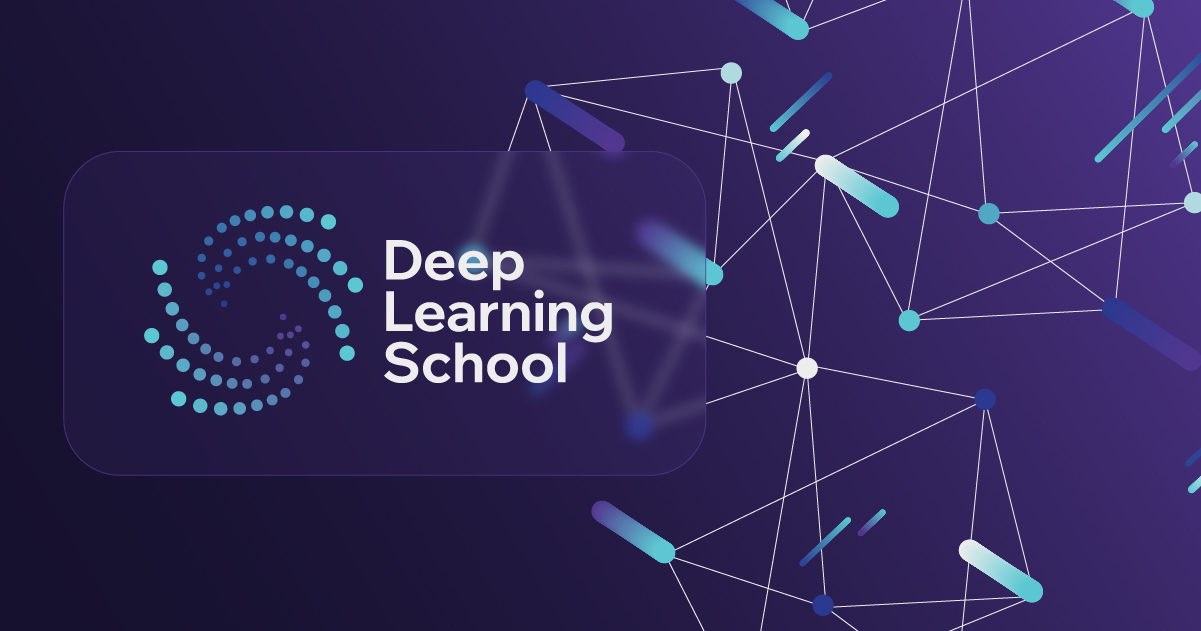

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Нейросетевая классификация текстов </b></h1>

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

In [ ]:
!pip install -q datasets

Импорт необходимых библиотек

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List
import string

import seaborn
seaborn.set(palette='summer')

In [ ]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [ ]:
# Загрузим датасет
dataset = datasets.load_dataset('fancyzhx/ag_news')

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

In [ ]:
dataset['train']

Dataset({
    features: ['text', 'label'],
    num_rows: 120000
})

In [ ]:
dataset['test']

Dataset({
    features: ['text', 'label'],
    num_rows: 7600
})

In [ ]:
dataset['train']['text'][:10]

["Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.",
 'Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\\which has a reputation for making well-timed and occasionally\\controversial plays in the defense industry, has quietly placed\\its bets on another part of the market.',
 "Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\\about the economy and the outlook for earnings are expected to\\hang over the stock market next week during the depth of the\\summer doldrums.",
 'Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\\flows from the main pipeline in southern Iraq after\\intelligence showed a rebel militia could strike\\infrastructure, an oil official said on Saturday.',
 'Oil prices soar to all-time record, posing new menace to US economy (A

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

In [ ]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
temp = 'Hi. i`m NLTK library,i can help with tokenization!!! and you?'
temp = temp.lower().translate(str.maketrans('','',string.punctuation))
word_tokenize(temp)




['hi',
 'im',
 'nltk',
 'libraryi',
 'can',
 'help',
 'with',
 'tokenization',
 'and',
 'you']

In [ ]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    proccessed_text = example.lower().translate(
        str.maketrans('','',string.punctuation)
    )

    for word in word_tokenize(proccessed_text):
        words[word]+=1

vocab = set(['<unk>','<bos>','<eos>','<pad>'])
counter_threshold=25

for word,q in words.items():
    if q>counter_threshold:
        vocab.add(word)

print(f'размер словаря: {len(vocab)}')

word2ind = {char: i for i,char in enumerate(vocab)}
ind2word = {i: char for char,i in word2ind.items()}


  0%|          | 0/120000 [00:00<?, ?it/s]

размер словаря: 11842


In [ ]:
len(word2ind)

11842

In [ ]:
print(word2ind['<bos>'])
print(word2ind['<eos>'])
print(word2ind['<unk>'])
print(word2ind['<pad>'])

5239
6301
9731
4818


In [ ]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(
            str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [
            word2ind.get(word, self.unk_id) for word in word_tokenize(processed_text)
            ]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [ ]:
train_dataset = WordDataset(dataset['train'])

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])),5000)
eval_dataset = WordDataset(dataset['test'].select(idx))

batch_size = 32
train_dataloader = DataLoader(
    train_dataset, shuffle=True,collate_fn=collate_fn_with_padding, batch_size=batch_size
)
eval_dataloader = DataLoader(
    eval_dataset, shuffle=False, collate_fn=collate_fn_with_padding,batch_size=batch_size
)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [ ]:
def evaluate(model, eval_dataloader) -> float:
    """
    Calculate accuracy on validation dataloader.
    """

    predictions = []
    target = []
    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids'])
            predictions.append(logits.argmax(dim=1))
            target.append(batch['label'])

    predictions = torch.cat(predictions)
    target = torch.cat(target)
    accuracy = (predictions == target).float().mean().item()

    return accuracy

## Ход работы
Оценка за домашнее задание складывается из четырех частей:
### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

# Эксперимент 1 (baseline)





model architecture

In [ ]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim:int,vocab_size:int,num_classes:int=4,
        aggregation_type:str='max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.RNN(hidden_dim,hidden_dim,batch_first=True)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction


In [ ]:
num_epoch = 5
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"Starting trainig for {aggregation_type}")
    losses = []
    acc = []

    model = CharLM(
        hidden_dim = 256,vocab_size=len(vocab),aggregation_type=aggregation_type
    ).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())

    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc = f'Training epoch {epoch}:')):
            optimizer.zero_grad()
            logits = model(batch['input_ids'])
            loss = criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

Starting trainig for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

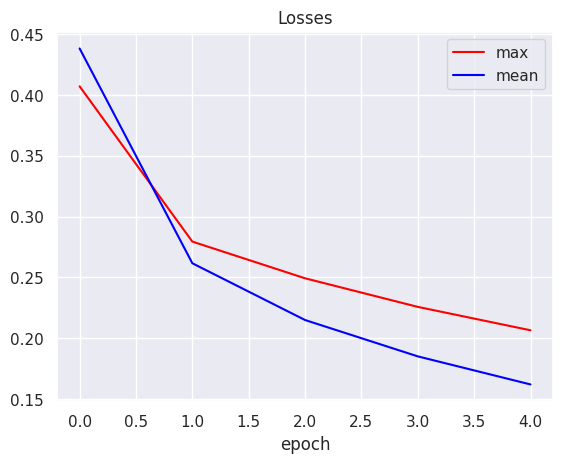

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), losses_type[name],color=color,label=name)

plt.title('Losses')
plt.xlabel('epoch')
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 90.62
Лучшая accuracy для подхода mean: 90.96


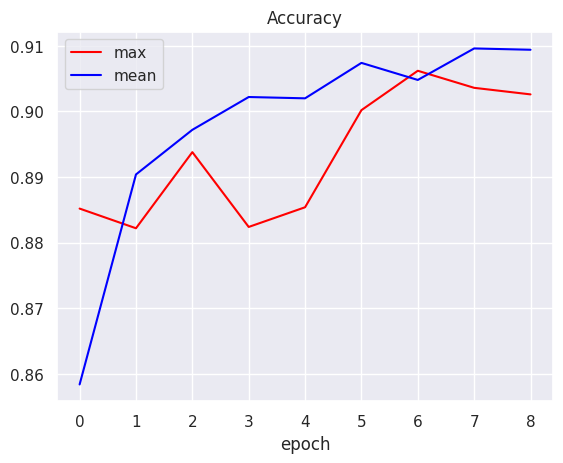

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:],color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accuracy')
plt.xlabel('epoch')
plt.legend()
plt.show()

итоговый score (baseline) для подхода max: 90.62, а для mean: 90.96

In [ ]:
import torch
from nltk.tokenize import word_tokenize

def predict_custom_sentence(sentence: str, model, word2ind, ind2word, device):

    model.eval()

    processed_text = sentence.lower().translate(
        str.maketrans('', '', string.punctuation)
    )

    tokens = word_tokenize(processed_text)

    bos_id = word2ind['<bos>']
    eos_id = word2ind['<eos>']
    unk_id = word2ind['<unk>']

    token_ids = [bos_id]
    token_ids += [word2ind.get(word, unk_id) for word in tokens]
    token_ids += [eos_id]

    input_tensor = torch.LongTensor([token_ids]).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        predicted_class_id = logits.argmax(dim=1).item()

        probabilities = torch.softmax(logits, dim=1).squeeze().tolist()

    return predicted_class_id, probabilities
classes_map = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

my_sentence = "Calif. Aims to Limit Farm-Related Smog (AP) AP - Southern California's smog-fighting agency went after emissions of the bovine variety Friday, adopting the nation's first rules to reduce air pollution from dairy cow manure."
class_id, probs = predict_custom_sentence(my_sentence, model, word2ind, ind2word, device)

print(f"Предложение: {my_sentence}")
print(f"Предсказанный класс: {classes_map[class_id]} (ID: {class_id})")
print("\nУверенность модели по всем классам:")
for cid, score in enumerate(probs):
    print(f" - {classes_map[cid]}: {score:.2%}")


Предложение: Calif. Aims to Limit Farm-Related Smog (AP) AP - Southern California's smog-fighting agency went after emissions of the bovine variety Friday, adopting the nation's first rules to reduce air pollution from dairy cow manure.
Предсказанный класс: Sci/Tech (ID: 3)

Уверенность модели по всем классам:
 - World: 1.01%
 - Sports: 0.00%
 - Business: 0.01%
 - Sci/Tech: 98.98%


In [ ]:
my_sentence = "The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\\team of rocketeers competing for the  #36;10 million Ansari X Prize, a contest for\\privately funded suborbital space flight, has officially announced the first\\launch date for its manned rocket."

class_id, probs = predict_custom_sentence(my_sentence, model, word2ind, ind2word, device)

print(f"Предложение: {my_sentence}")
print(f"Предсказанный класс: {classes_map[class_id]} (ID: {class_id})")
print("\nУверенность модели по всем классам:")
for cid, score in enumerate(probs):
    print(f" - {classes_map[cid]}: {score:.2%}")


Предложение: The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\team of rocketeers competing for the  #36;10 million Ansari X Prize, a contest for\privately funded suborbital space flight, has officially announced the first\launch date for its manned rocket.
Предсказанный класс: Sci/Tech (ID: 3)

Уверенность модели по всем классам:
 - World: 0.01%
 - Sports: 0.02%
 - Business: 0.14%
 - Sci/Tech: 99.83%


In [ ]:
my_sentence = "Genry Ford invented 1st american popular car"

class_id, probs = predict_custom_sentence(my_sentence, model, word2ind, ind2word, device)

print(f"Предложение: {my_sentence}")
print(f"Предсказанный класс: {classes_map[class_id]} (ID: {class_id})")
print("\nУверенность модели по всем классам:")
for cid, score in enumerate(probs):
    print(f" - {classes_map[cid]}: {score:.2%}")


Предложение: Genry Ford invented 1st american popular car
Предсказанный класс: Business (ID: 2)

Уверенность модели по всем классам:
 - World: 0.00%
 - Sports: 0.02%
 - Business: 85.46%
 - Sci/Tech: 14.51%


# Эксперимент 2 (GRU instead of default RNN)

определим GRU model

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.gru = nn.GRU(hidden_dim,hidden_dim,batch_first=True)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.gru(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 5
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 4::   0%|          | 0/3750 [00:00<?, ?it/s]

In [ ]:
import matplotlib.pyplot as plt
from importlib import reload

reload(plt)

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

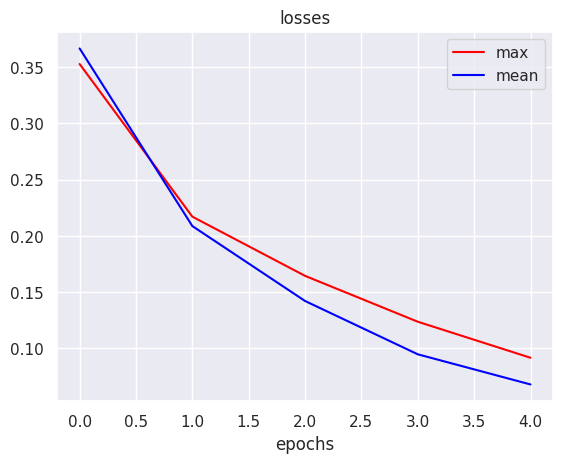

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.40
Лучшая accuracy для подхода mean: 91.32


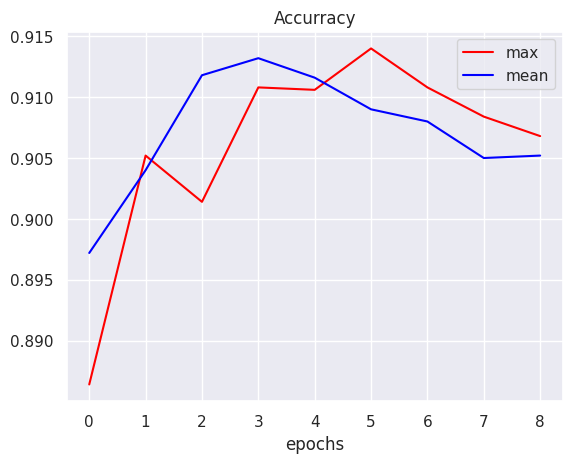

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"{max(acc_type['max']):.3f}")

0.914


In [ ]:
print(f"{max(acc_type['mean']):.3f}")

0.913


# Experiment 3 (increasing num of layers, model - GRU)



model architecture

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.gru = nn.GRU(hidden_dim,hidden_dim,batch_first=True,num_layers=2)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.gru(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 5
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 4::   0%|          | 0/3750 [00:00<?, ?it/s]

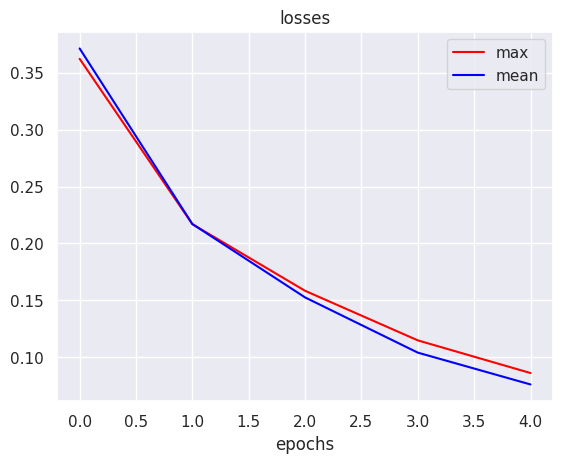

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.66
Лучшая accuracy для подхода mean: 91.40


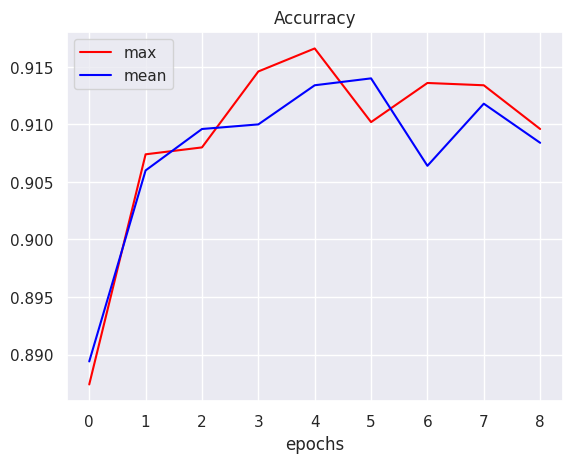

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"{max(acc_type['max']):.3f}")

0.917


In [ ]:
print(f"{max(acc_type['mean']):.3f}")

0.914


# experiment 4(adding to the experiment 3 model inherit dropout between GRU layers)

model architecture

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.gru = nn.GRU(hidden_dim,hidden_dim,batch_first=True,num_layers=2,dropout=0.1)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.gru(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 5
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 4::   0%|          | 0/3750 [00:00<?, ?it/s]

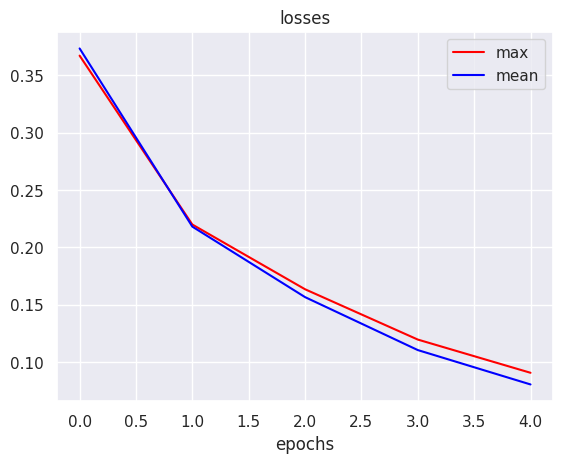

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.78
Лучшая accuracy для подхода mean: 91.14


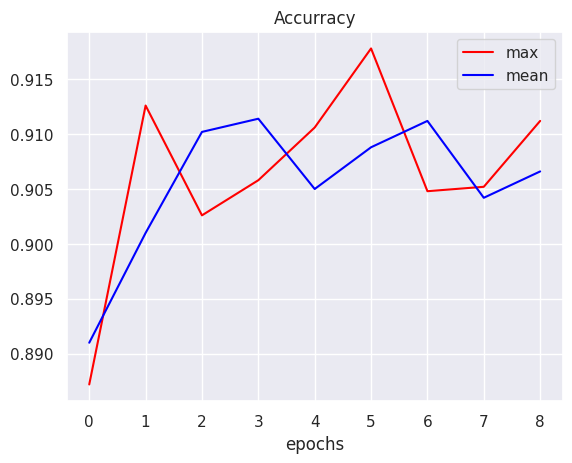

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"{max(acc_type['max']):.3f}")
print(f"{max(acc_type['mean']):.3f}")

0.918
0.911


# Experiment 5(using LSTM)

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.lstm = nn.LSTM(hidden_dim,hidden_dim,batch_first=True,num_layers=1,)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.lstm(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 5
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 4::   0%|          | 0/3750 [00:00<?, ?it/s]

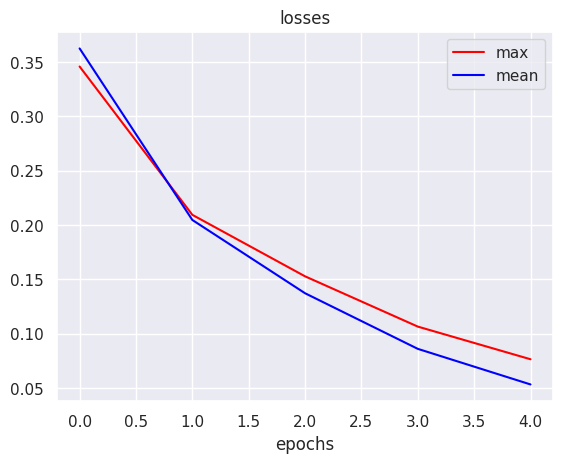

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.32
Лучшая accuracy для подхода mean: 91.58


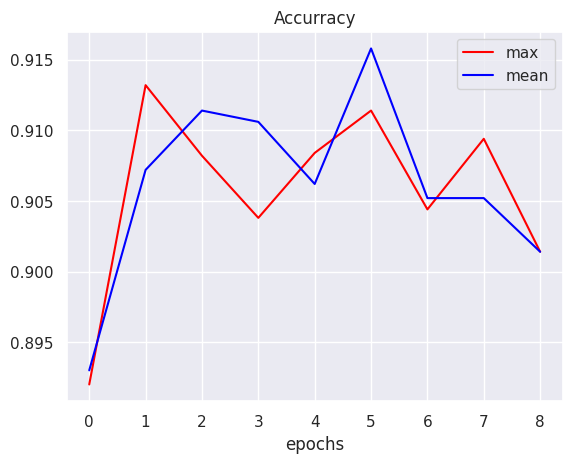

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"max: {max(acc_type['max']):.3f}")
print(f"mean: {max(acc_type['mean']):.3f}")

max: 0.913
mean: 0.916


# experiment 6(like exp5 but more epochs)

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.lstm = nn.LSTM(hidden_dim,hidden_dim,batch_first=True,num_layers=1,)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.lstm(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 10
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 5::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 6::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 7::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 8::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 9::   0%|          | 0/3750 [00:00<?, ?it/s]

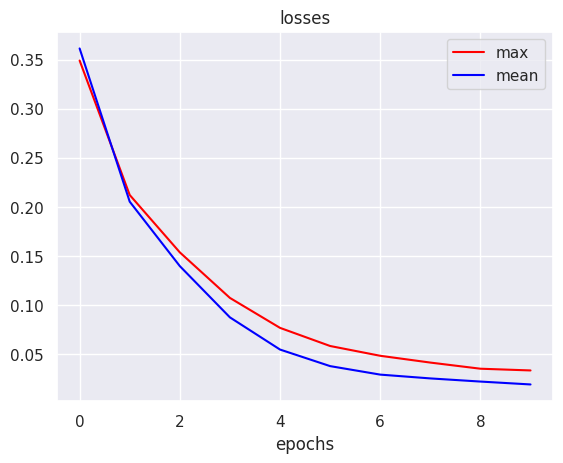

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.00
Лучшая accuracy для подхода mean: 91.48


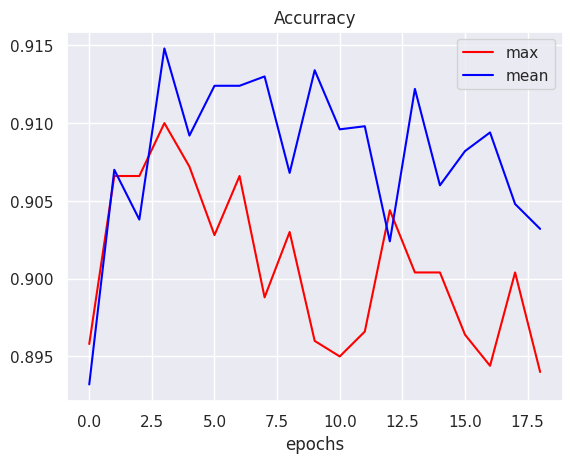

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"max: {max(acc_type['max']):.3f}")
print(f"mean: {max(acc_type['mean']):.3f}")

max: 0.910
mean: 0.915


# experiment 7(changing architecture afterr GRU applying)

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.gru = nn.GRU(hidden_dim,hidden_dim,batch_first=True,num_layers=1,)
        self.linear = nn.Linear(hidden_dim*2,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.gru(embeddings)

        if self.aggregation_type == 'max':
            agg_output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            agg_output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        last_token_output = output[:,-1,:]

        combined__output = torch.cat([agg_output,last_token_output],dim=1)

        output = self.dropout(self.linear(self.non_lin(combined__output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 5
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 4::   0%|          | 0/3750 [00:00<?, ?it/s]

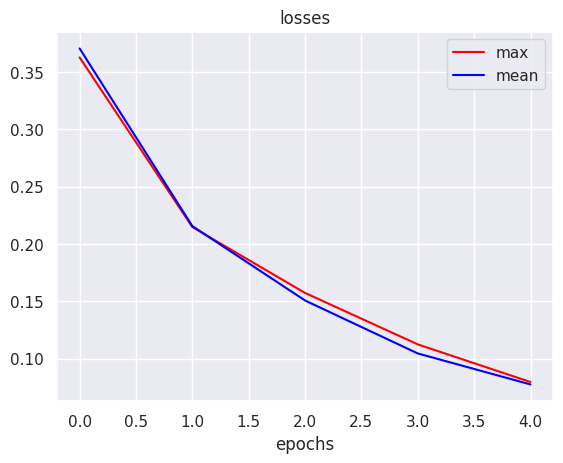

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.46
Лучшая accuracy для подхода mean: 91.42


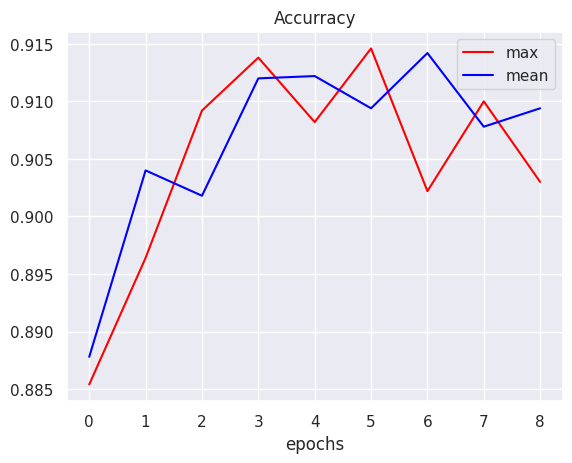

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"max: {max(acc_type['max']):.3f}")
print(f"mean: {max(acc_type['mean']):.3f}")

max: 0.915
mean: 0.914


# exp 8(baseline but with more epochs)

возьмем baseline model и будем обучать 10 эпох вместо 5. это разумно сделать поскольку на графиках 1-ого эксперимента видно что сходимость по losses еще не достигнута, и что accuracy еще не скачет и что есть потенциал роста.

In [ ]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim:int,vocab_size:int,num_classes:int=4,
        aggregation_type:str='max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.RNN(hidden_dim,hidden_dim,batch_first=True)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction


In [ ]:
num_epoch = 10
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"Starting trainig for {aggregation_type}")
    losses = []
    acc = []

    model = CharLM(
        hidden_dim = 256,vocab_size=len(vocab),aggregation_type=aggregation_type
    ).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())

    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc = f'Training epoch {epoch}:')):
            optimizer.zero_grad()
            logits = model(batch['input_ids'])
            loss = criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

Starting trainig for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 5::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 6::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 7::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 8::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 9::   0%|          | 0/3750 [00:00<?, ?it/s]

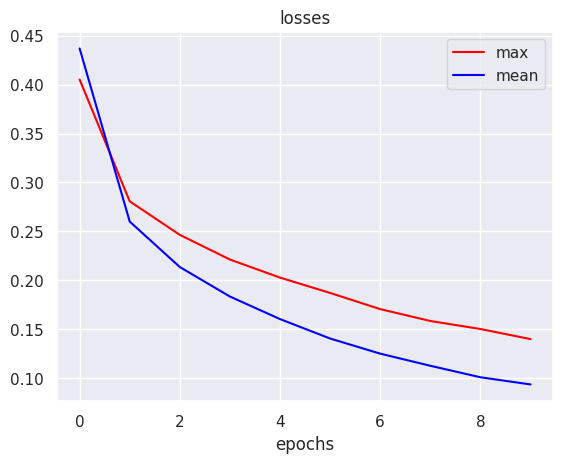

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 90.68
Лучшая accuracy для подхода mean: 90.94


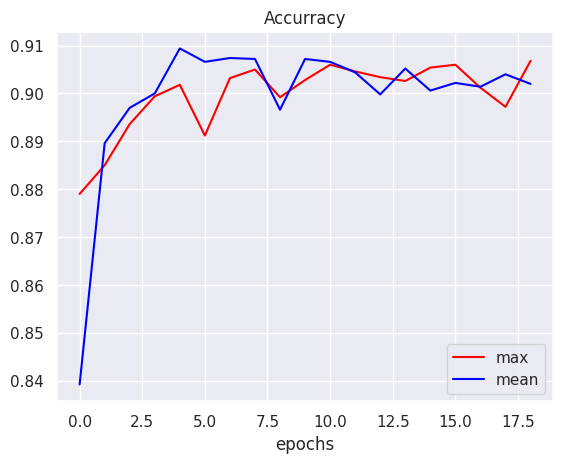

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"max: {max(acc_type['max']):.3f}")
print(f"mean: {max(acc_type['mean']):.3f}")

max: 0.907
mean: 0.909


таким образом идея увелечения кол-ва эпох обучения не оправдала себя. на 5й эпохе accuracy модели перестает улучшаться, при этом loss уменьшается что свидетельсвует о том что модель предсказывает один и тот же класс но увеличивает при этом свою уверенность в данном классе. это так потому что CrossEntropyLoss использует softmax и соотвестенно корректируют свою уверенность в классе, но не меняет на другой.

# exp 9 (trying to learn best model using gru and inreasing num of layers and epochs we learn. also i increased dropout so it doesn't overfitting)

In [ ]:
class CharLm(nn.Module):
    def __init__(self,hidden_dim:int,vocab_size:int,num_classes:int=4,aggregation_type:str='max'):
        super().__init__()
        self.embedding =nn.Embedding(vocab_size,hidden_dim)
        self.gru = nn.GRU(hidden_dim,hidden_dim,batch_first=True,num_layers=3,dropout=0.3)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self,input_batch)->torch.Tensor:
        embeddings = self.embedding(input_batch)
        output,_ = self.gru(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
num_epoch = 7
eval_steps = len(train_dataloader)//2

losses_type = {}
acc_type = {}

for aggregation_type in ['max','mean']:
    print(f"starting training for {aggregation_type}")
    losses=[]
    acc=[]

    model = CharLm(hidden_dim=256,vocab_size=len(vocab),aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model.parameters())


    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f"training for {epoch}:")):
            optimizer.zero_grad()
            logits=model(batch['input_ids'])
            loss=criterion(logits,batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps==0:
                model.eval()
                acc.append(evaluate(model,eval_dataloader))
                model.train()
        losses.append(sum(epoch_losses)/len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

starting training for max


training for 0::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 1::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

training for 2::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 3::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 4::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 5::   0%|          | 0/3750 [00:00<?, ?it/s]

training for 6::   0%|          | 0/3750 [00:00<?, ?it/s]

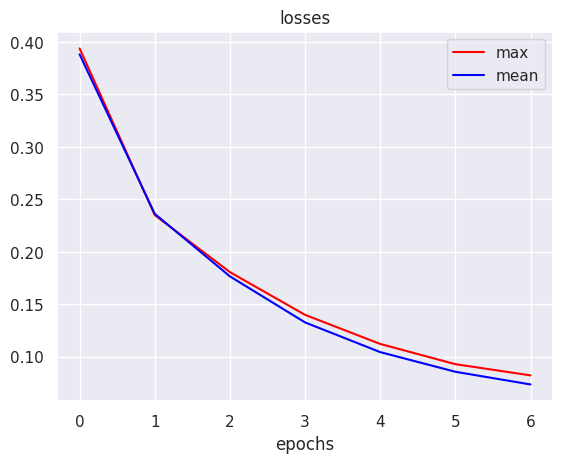

In [ ]:
for (name,values), color in zip(losses_type.items(),['red','blue']):
    plt.plot(np.arange(len(losses_type[name])), values, color=color,label=name)

plt.title("losses")
plt.xlabel("epochs")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.30
Лучшая accuracy для подхода mean: 91.38


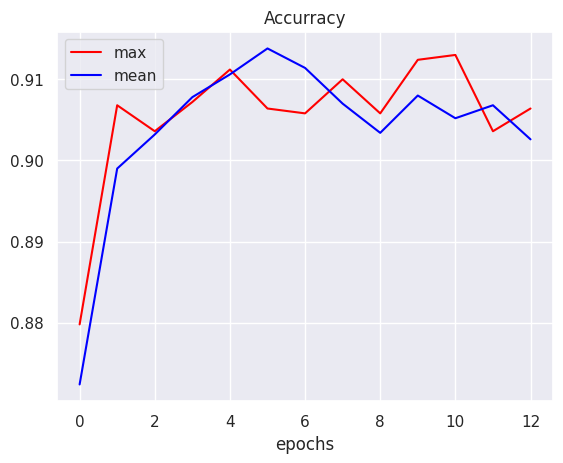

In [ ]:
for (name,values), color in zip(acc_type.items(),['red','blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), values[1:], color=color,label=name)
    print(f"Лучшая accuracy для подхода {name}: {max(acc_type[name])*100:.2f}")

plt.title('Accurracy')
plt.xlabel('epochs')
plt.legend()
plt.show()

In [ ]:
print(f"max: {max(acc_type['max']):.3f}")
print(f"mean: {max(acc_type['mean']):.3f}")

max: 0.913
mean: 0.914


безуспешно(

#Отчет:

exp1: baseline model дала хороший начальный скор. по графикам я предположил что модель не дообучилась и ее скор может улучшиться но проведя exp8 увеличив кол-во эпох скор не изменился. график accuracy у восьмой модели оказался стабильным, учитывая падение лосса это может означать что сходимости после 5й эпохи нет и это оптимальное время обучения для данной модели. лучшая accuracy 0.910

в exp2 я обучил gru model она дала прирост(0.917 против 0.910). loss на протяжении всего обучения стабильно уменьшался но accuracy после 2-3 эпохи достигла максимума и пошла на спад поэтому 3 эпохи для данной модели- оптимально.

exp3 дал выше скор засчет использования gru и увелечения кол-ва слоев, благодаря чему модель способна улавливать более глубокие связи.

в exp4 был добавлен dropout между внутреннеми слоями gru что должно предотвратить переобучение модели. таким образом скор незначительно подрос по сравнению с exp3 а именно до 0.918

в exp5 была исопльзована архитектура lstm. по скору она на уровне gru.график скора после 2й эпохи колеблется и не увеличивается так что обучение до 2й эпохи оптимально.

exp6 повторяет exp5 но было увеличено кол-во эпох чтобы проверить сходимость loss and accuaracy но loss после 6й эпохи перестал уменьшатся а скор не улучшился а только колебался таким образом увелечения кол-ва эпох после определенного момента а именно 3-4 эпохи для данной модели не дает прироста качества.

exp8 как уже говорилось выше такой же как exp1 но с большим кол-вом эпох. это проверка гипотезы о том что 1я модель недообучилась судя по графикам. но она не оправдалась.
exp9 являлся попыткой получить лучший скор объединяя лучшие практики до а именно gru model +внутренний dropout + увелечние кол-ва слоев до 3. подход не оправдал себя. скор получился не лучшим. на графике accuracy видно что после 3-4 эпохи модель достигла предела по accuracy затем начались колебания и снижение. loss стабильно уменьшался как и во многих экспериментах до что свидетельствует не об измении классов когда модель предсказывает а лишь увелечение ее уверенности в классе даже если он не правильный. когда же класс правильный loss уменьшается.

оптимальной получилась модель из exp4 поскольку у нее наилучший скор а время обучения одно из наименьших.

Лучший скор у эксперимента 4  - 0.918